# What each CPG knob does

Last full run: 2026-10-23 to 24, 4 h 11 min, AMD Ryzen 7 5800, 16 workers (105,000 trials of 3 walks each in 4.17 h, the sweeps in 57 s).

Every CPG has tunable parameters (one `phase`, `w`, `amplitudes` and `offset` per hinge, plus a few model-specific groups) and constants its constructor fixes, which no search has touched so far: the coupling strength, how fast an oscillator settles back onto its cycle, and a few more. This notebook asks two questions for each of the seven CPGs on the gecko.

1. **Search everything.** CMA-ES tunes the gait and the constants together, three seeds per CPG. Which constants do the winners pick, and do the seeds agree? A constant the seeds agree on and that moves far from its default was holding the gaits back; one that lands anywhere is one the gait does not care about.
2. **Turn one knob at a time.** From each CPG's best result, each parameter group and each constant is moved alone over a range, and the trial measures what changes: distance, turning and servo strain.

The score rewards a gait that walks, that turns both ways under a mirrored input, and that asks no hinge to move faster than the SER0019 servo can (the user's choice, 2026-10-23).

In [1]:
# Run time: the last code cell prints how long the whole notebook took
import sys
import time

sys.stdout.write(f"Started {time.strftime('%Y-%m-%d %H:%M:%S %Z')}\n")
NOTEBOOK_STARTED = time.perf_counter()

Started 2026-10-23 23:31:26 UTC


In [2]:
# Standard library
import json
import math
import os

# Third-party libraries
import matplotlib.pyplot as plt
import nevergrad as ng
import numpy as np
from rich.console import Console

# Local libraries
from ariel import DATA
from ariel.simulation import (
    AdaptiveHopfCPG,
    HopfCPG,
    LearnableTegotaeCPG,
    NaCPG,
    PhaseCPG,
    SwingStanceCPG,
    TegotaeCPG,
    process_pool,
)

%matplotlib inline
plt.rcParams["figure.dpi"] = 50  # keeps the notebook small
console = Console()

MODELS = [
    HopfCPG,
    AdaptiveHopfCPG,
    PhaseCPG,
    SwingStanceCPG,
    NaCPG,
    TegotaeCPG,
    LearnableTegotaeCPG,
]
BUDGET = 5000  # trials per search
SEEDS = [0, 1, 2]
WORKERS = os.cpu_count()  # pool processes
OUT = DATA / "cpg_knobs"
OUT.mkdir(parents=True, exist_ok=True)
PROGRESS = OUT / "progress.log"
REPORT_EVERY = 600.0  # seconds between progress lines

# The constants each constructor fixes: (lowest, highest, default).
# Searched on a log scale. Settling rates stop at 80 because the CPGs
# take Euler steps of 0.01 s, which become unstable near rate x step
# = 1; the Tegotae models default to coupling 0, which a log scale
# cannot reach, so they start from its lowest value, 0.001.
COUPLING = (0.1, 10.0, 1.0)
CONSTANTS = {
    "HopfCPG": {"coupling": COUPLING, "gamma": (1.0, 80.0, 10.0)},
    "AdaptiveHopfCPG": {
        "coupling": COUPLING,
        "gamma": (1.0, 80.0, 10.0),
        "epsilon": (0.1, 10.0, 1.0),
    },
    "PhaseCPG": {
        "coupling": COUPLING,
        "convergence": (1.0, 80.0, 20.0),
    },
    "SwingStanceCPG": {
        "coupling": COUPLING,
        "alpha": (1.0, 80.0, 5.0),
        "beta": (5.0, 80.0, 50.0),
        "steepness": (10.0, 300.0, 100.0),
    },
    "NaCPG": {"coupling": COUPLING, "alpha": (3.0, 80.0, 30.0)},
    "TegotaeCPG": {"coupling": (0.001, 10.0, 0.001)},
    "LearnableTegotaeCPG": {"coupling": (0.001, 10.0, 0.001)},
}

In [3]:
# The trial lives in gecko_trials.py, beside this notebook: a pool
# worker can import a function from a file, never from a notebook cell
from gecko_trials import (
    TOP_SPEED,
    Knob,
    Walked,
    knob_trial,
    lockstep,
    walker,
)

## The trial and the score

One trial (`knob_trial` in `gecko_trials.py`) walks the gecko three times for 10 s on the flat floor: with no input, with a turn input (spine hinges bent 0.2 rad, the left legs swinging 30% wider and the right 30% narrower, the strongest steering input in the controllability check of 2026-10-23), and with its mirror. It measures:

- **distance**: how far the core moved in the walk with no input;
- **turn**: half the difference between the two mirrored walks' turning rates, after the first 2 s (a gait that turns 8 deg/s left under one input and 4 deg/s right under the other scores 6 deg/s, whatever its own drift);
- **overspeed**: the share of hinge steps whose command moves faster than the servo's top speed, 5.82 rad/s, over all three walks;
- **rhythm spread**: in the walk with no input, (fastest - slowest) / median of the hinges' main frequencies; 0 when every moving hinge keeps one rhythm.

The score adds them, in metres:

`score = distance + 0.1 x min(turn, 15) x min(1, distance / 0.5) - 2 x overspeed`

Worked example: a gait walking 1.6 m with a turn of 2.7 deg/s and 17% overspeed (HopfCPG's best gait from `cpg_locomotion`) scores 1.6 + 0.27 - 0.34 = 1.53. Turning is worth at most 1.5 m, at 15 deg/s, and only a gait that walks at least 0.5 m earns all of it, so spinning in place does not pay. A gait that overdrives the servo all the time loses 2 m. The weights are judgement: 10 deg/s of steering is worth about as much as a metre of walking.

In [4]:
TURN_WEIGHT = 0.1  # metres of score per deg/s of turn
TURN_CAP = 15.0  # deg/s
WALKS = 0.5  # metres in 10 s for the full turn credit
SERVO_WEIGHT = 2.0  # metres of score for always overdriving


def turn_of(walked):
    """Return half the gap between the two mirrored turning rates.

    Returns
    -------
    float
        Degrees per second.
    """
    return abs(walked.turn_plus - walked.turn_minus) / 2


def score(walked):
    """Score one trial: walking, steering, servo strain.

    Returns
    -------
    float
        The score in metres; higher is better.
    """
    walking = min(1.0, walked.distance / WALKS)
    turn = min(turn_of(walked), TURN_CAP)
    return (
        walked.distance
        + TURN_WEIGHT * walking * turn
        - SERVO_WEIGHT * walked.overspeed
    )


example = Walked(
    distance=1.6,
    turn_plus=-9.0,
    turn_minus=-3.6,
    drift=-5.5,
    overspeed=0.17,
    end_stop=0.04,
    rhythm_spread=0.0,
    seconds=1.0,
)
console.print(
    f"worked example: turn {turn_of(example):.1f} deg/s, score"
    f" {score(example):.2f} m; servo top speed {TOP_SPEED:.2f} rad/s"
)

worked example: turn 2.7 deg/s, score 1.53 m; servo top speed 5.82 rad/s

In [5]:
# Checks: the worked example scores as the text says, and turning
# without walking earns nothing
EXAMPLE_SCORE = 1.53
TOLERANCE = 0.01
assert abs(score(example) - EXAMPLE_SCORE) < TOLERANCE
spinner = example.model_copy(update={"distance": 0.0, "overspeed": 0.0})
assert abs(score(spinner)) < TOLERANCE

## Part 1: search everything

Each search runs CMA-ES in the unit cube. The first numbers of a point are the gait, scaled to the CPG's own bounds as in `cpg_locomotion`; the last ones are the constants, mapped onto their ranges on a log scale. A search starts from the CPG's own seeded random gait and the constants' defaults. All 21 searches (7 CPGs x 3 seeds) run together on the process pool, one CMA-ES generation of each per round, and the notebook appends a line to `__data__/cpg_knobs/progress.log` every 10 minutes with each CPG's best score so far.

In [6]:
gecko = walker()
adjacency = gecko.adjacency


class Search:
    """One CMA-ES search over a CPG's gait and constants."""

    def __init__(self, cpg_class, seed):
        cpg = cpg_class(adjacency, seed=seed)
        self.name = cpg_class.__name__
        self.lower, self.upper = (
            b.numpy().astype(np.float64) for b in cpg.parameter_bounds()
        )
        self.constants = CONSTANTS[self.name]
        self.log_low = np.log([lo for lo, _, _ in self.constants.values()])
        self.log_high = np.log([hi for _, hi, _ in self.constants.values()])
        defaults = np.log([d for _, _, d in self.constants.values()])
        start = np.concatenate([
            (cpg.get_flat_params().numpy() - self.lower)
            / (self.upper - self.lower),
            (defaults - self.log_low) / (self.log_high - self.log_low),
        ])
        parametrization = ng.p.Array(shape=start.shape, lower=0, upper=1)
        parametrization.value = np.clip(start, 0, 1)
        parametrization.random_state = np.random.RandomState(seed)
        self.optimizer = ng.optimizers.CMA(
            parametrization=parametrization, budget=BUDGET
        )
        self.size = len(self.lower)

    def job(self, point):
        """Turn a point of the unit cube into a trial.

        Returns
        -------
        Knob
            The gait and the constants the point stands for.
        """
        params = self.lower + point[: self.size] * (self.upper - self.lower)
        logs = self.log_low + point[self.size :] * (
            self.log_high - self.log_low
        )
        return Knob(
            cpg=self.name,
            params=params.tolist(),
            constants=dict(
                zip(self.constants, np.exp(logs).tolist(), strict=True)
            ),
        )


searches = {
    (cpg_class.__name__, seed): Search(cpg_class, seed)
    for cpg_class in MODELS
    for seed in SEEDS
}
trials = {key: [] for key in searches}  # (Knob, Walked) per trial
last_report = time.perf_counter()
PROGRESS.write_text(
    f"{time.strftime('%H:%M:%S')} start: {len(searches)} searches of"
    f" {BUDGET} trials on {WORKERS} workers\n"
)


def report(*, final=False):
    """Append each CPG's best score so far to the progress log."""
    lines = []
    for cpg_class in MODELS:
        name = cpg_class.__name__
        done = [len(trials[name, seed]) for seed in SEEDS]
        best = [
            max((score(w) for _, w in trials[name, seed]), default=math.nan)
            for seed in SEEDS
        ]
        lines.append(
            f"  {name:20s} {min(done):5d}/{BUDGET} trials, best score per"
            f" seed {np.round(best, 3).tolist()}"
        )
    stamp = time.strftime("%H:%M:%S")
    with PROGRESS.open("a") as log:
        log.write(f"{stamp} {'final' if final else 'progress'}\n")
        log.write("\n".join(lines) + "\n")


def evaluate(asked):
    """Score one round of candidates in the pool.

    Returns
    -------
    list[float]
        Minus each score, since CMA-ES minimises.
    """
    global last_report  # ruff: ignore[global-statement]  # a notebook-level clock
    jobs = [searches[key].job(candidate.value) for key, _, candidate in asked]
    walked = list(pool.map(knob_trial, jobs))
    for (key, _, _), job, result in zip(asked, jobs, walked, strict=True):
        trials[key].append((job, result))
    if time.perf_counter() - last_report > REPORT_EVERY:
        report()
        last_report = time.perf_counter()
    return [-score(result) for result in walked]


started = time.perf_counter()
with process_pool(WORKERS) as pool:
    told = lockstep(
        {key: search.optimizer for key, search in searches.items()},
        BUDGET,
        evaluate,
    )
search_seconds = time.perf_counter() - started
report(final=True)

best = {}  # (name, seed): (score, Knob, Walked) of the first best trial
for key, done in trials.items():
    scores = [score(w) for _, w in done]
    first = int(np.argmax(scores))
    best[key] = (scores[first], *done[first])
(OUT / "best.json").write_text(
    json.dumps(
        {
            f"{name}/{seed}": {
                "score": value,
                "knob": job.model_dump(),
                "walked": walked.model_dump(),
            }
            for (name, seed), (value, job, walked) in best.items()
        },
        indent=1,
    )
)
console.print(
    f"{len(searches)} searches, {BUDGET * len(searches)} trials in"
    f" {search_seconds / 3600:.2f} h on {WORKERS} workers"
)

21 searches, 105000 trials in 4.17 h on 16 workers

In [7]:
# Checks: every search ran to its full budget with finite scores, and
# the told values are minus the scores
for key, done in trials.items():
    assert len(done) == BUDGET, key
    assert all(math.isfinite(score(w)) for _, w in done), key
    assert told[key][0][1] == -score(done[0][1]), key

### Results of the search

Best score so far against trials, median of the three seeds, with the range between the worst and the best seed shaded. Then, per CPG and seed, what the best trial measured and which constants it chose, next to their defaults.

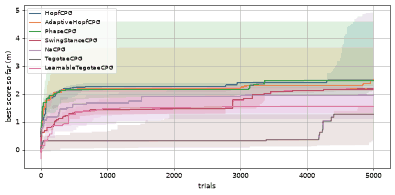

CPG                  seed  score dist m  turn  drift  over  stop rhythm  constants (default)

HopfCPG                 0   2.47   1.32  14.6   +2.3  0.16  0.02   0.00  coupling 0.882 (1), gamma 10.2 (10)

HopfCPG                 1   2.26   1.61  16.2   -0.7  0.43  0.08   0.00  coupling 1.01 (1), gamma 19.8 (10)

HopfCPG                 2   4.92   3.75  15.4   +3.6  0.17  0.04   0.00  coupling 0.998 (1), gamma 13 (10)

AdaptiveHopfCPG         0   2.30   1.32  11.8   -0.0  0.10  0.02   0.00  coupling 0.93 (1), gamma 11.7 (10), 
epsilon 0.433 (1)

...

TegotaeCPG              1   1.26   0.44  11.6   -8.8  0.10  0.04   3.00  coupling 0.00131 (0.001)

TegotaeCPG              2   1.52   0.76   9.7   -6.0  0.10  0.07   0.92  coupling 0.00167 (0.001)

LearnableTegotaeCPG     0   1.55   0.63  15.2   -5.2  0.29  0.07   1.30  coupling 0.00184 (0.001)

LearnableTegotaeCPG     1   1.31   0.56  10.5   -5.7  0.15  0.05   1.73  coupling 0.002 (0.001)

LearnableTegotaeCPG     2   1.96   0.89  15.1   +3.5  0.22  0.06   1.50  coupling 0.00194 (0.001)

In [8]:
fig, ax = plt.subplots(figsize=(8, 4))
for cpg_class in MODELS:
    name = cpg_class.__name__
    curves = np.array([
        np.maximum.accumulate([score(w) for _, w in trials[name, seed]])
        for seed in SEEDS
    ])
    x = np.arange(1, BUDGET + 1)
    ax.plot(x, np.median(curves, axis=0), label=name)
    ax.fill_between(x, curves.min(axis=0), curves.max(axis=0), alpha=0.15)
ax.set_xlabel("trials")
ax.set_ylabel("best score so far (m)")
ax.legend(fontsize=8)
ax.grid(visible=True)
fig.tight_layout()
plt.show()

console.print(
    f"{'CPG':20s} {'seed':>4s} {'score':>6s} {'dist m':>6s}"
    f" {'turn':>5s} {'drift':>6s} {'over':>5s} {'stop':>5s}"
    f" {'rhythm':>6s}  constants (default)"
)
for (name, seed), (value, job, w) in best.items():
    chosen = ", ".join(
        f"{c} {v:.3g} ({CONSTANTS[name][c][2]:g})"
        for c, v in job.constants.items()
    )
    console.print(
        f"{name:20s} {seed:4d} {value:6.2f} {w.distance:6.2f}"
        f" {turn_of(w):5.1f} {w.drift:+6.1f} {w.overspeed:5.2f}"
        f" {w.end_stop:5.2f} {w.rhythm_spread:6.2f}  {chosen}"
    )

In [9]:
# Checks: every CPG's best trial walks, and the best score per CPG is
# at least the score of its starting point
WALKED = 0.1  # metres in 10 s
for (name, seed), (value, _, w) in best.items():
    assert w.distance > WALKED, (name, seed)
    assert value >= score(trials[name, seed][0][1]), (name, seed)

## Part 2: turn one knob at a time

From each CPG's best trial over the three seeds, each knob is moved alone and the trial rerun:

- a constant over 7 values spread evenly on a log scale across its search range;
- `offset` and `b` (centre angles) shifted by -0.3 to +0.3 rad;
- `phase` by scaling every hinge's phase difference to hinge 0 by 0 to 2 (0 puts every hinge in step, 2 doubles every lag);
- every other group multiplied by 0 to 1.5, then clipped to its bounds.

Each panel shows one knob: distance (m), turn (deg/s / 10) and overspeed (share), with the best trial's own setting marked by the dotted line.

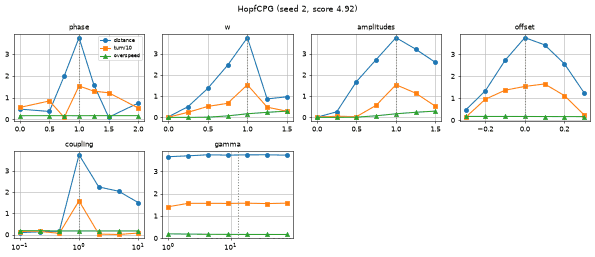

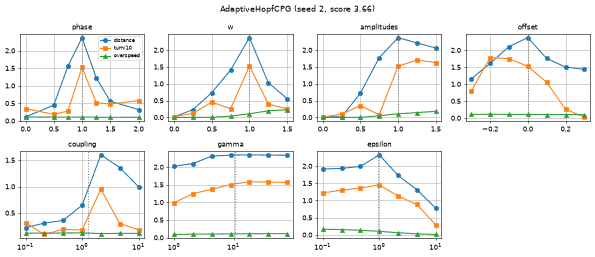

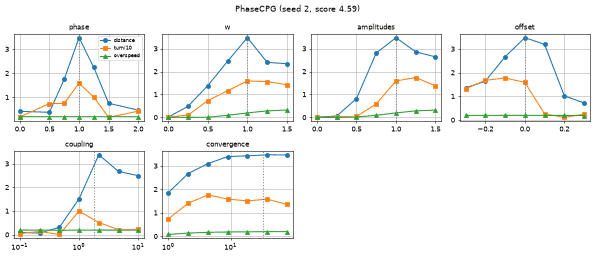

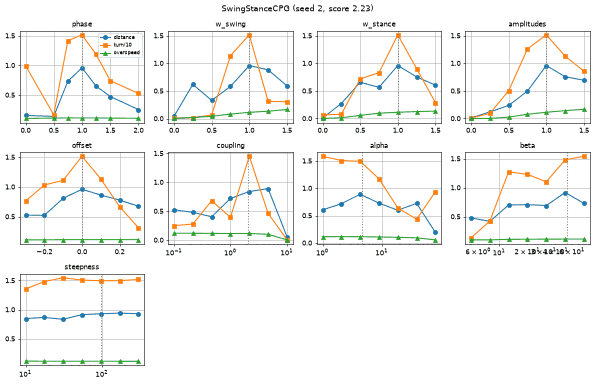

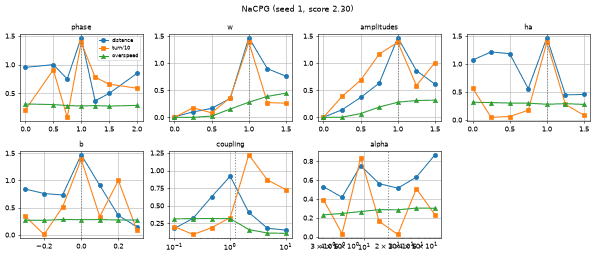

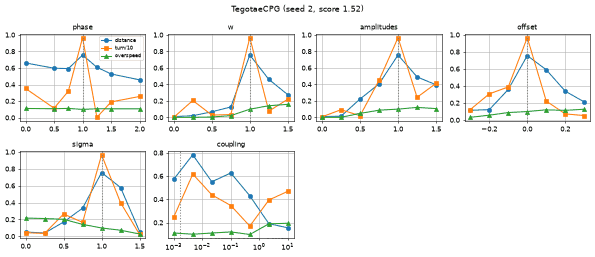

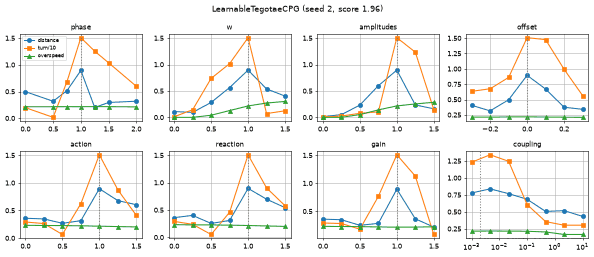

In [10]:
FACTORS = [0.0, 0.25, 0.5, 0.75, 1.0, 1.25, 1.5]
SHIFTS = [-0.3, -0.2, -0.1, 0.0, 0.1, 0.2, 0.3]
PHASE_FACTORS = [0.0, 0.5, 0.75, 1.0, 1.25, 1.5, 2.0]


def variants(name, job):
    """List the one-knob changes of a trial.

    Returns
    -------
    dict[str, tuple[list[float], list[Knob], float]]
        Per knob: the x values, the trials, and the best's own x.
    """
    cpg = CLASSES_BY_NAME[name](adjacency)
    lower, upper = (b.numpy() for b in cpg.parameter_bounds())
    params = np.array(job.params)
    out = {}
    start = 0
    for group, size in cpg.group_sizes.items():
        part = slice(start, start + size)
        start += size
        if group in {"offset", "b"}:
            xs, own = SHIFTS, 0.0
            values = [params[part] + s for s in SHIFTS]
        elif group == "phase":
            xs, own = PHASE_FACTORS, 1.0
            p = params[part]
            values = [(p[0] + f * (p - p[0])) % (2 * math.pi) for f in xs]
        else:
            xs, own = FACTORS, 1.0
            values = [params[part] * f for f in FACTORS]
        knobs = []
        for value in values:
            changed = params.copy()
            changed[part] = np.clip(value, lower[part], upper[part])
            knobs.append(job.model_copy(update={"params": changed.tolist()}))
        out[group] = (xs, knobs, own)
    for constant, (low, high, _) in CONSTANTS[name].items():
        xs = np.geomspace(low, high, 7).tolist()
        knobs = [
            job.model_copy(update={"constants": {**job.constants, constant: x}})
            for x in xs
        ]
        out[constant] = (xs, knobs, job.constants[constant])
    return out


CLASSES_BY_NAME = {cpg_class.__name__: cpg_class for cpg_class in MODELS}
winners = {}
for cpg_class in MODELS:
    name = cpg_class.__name__
    seed = max(SEEDS, key=lambda s, n=name: best[n, s][0])
    winners[name] = (seed, *best[name, seed])
sweeps = {name: variants(name, w[2]) for name, w in winners.items()}
jobs = [
    knob
    for per_knob in sweeps.values()
    for _, knobs, _ in per_knob.values()
    for knob in knobs
]
started = time.perf_counter()
with process_pool(WORKERS) as pool:
    swept = iter(pool.map(knob_trial, jobs))
    sweep_results = {
        name: {
            knob: [next(swept) for _ in knobs]
            for knob, (_, knobs, _) in per_knob.items()
        }
        for name, per_knob in sweeps.items()
    }
with PROGRESS.open("a") as log:
    log.write(
        f"{time.strftime('%H:%M:%S')} sweeps done: {len(jobs)} trials in"
        f" {time.perf_counter() - started:.0f} s\n"
    )

for name, per_knob in sweeps.items():
    columns = 4
    rows = math.ceil(len(per_knob) / columns)
    fig, axes = plt.subplots(
        rows, columns, figsize=(12, 2.6 * rows), squeeze=False
    )
    for ax, (knob, (xs, _, own)) in zip(
        axes.flat, per_knob.items(), strict=False
    ):
        got = sweep_results[name][knob]
        ax.plot(xs, [w.distance for w in got], "o-", label="distance")
        ax.plot(xs, [turn_of(w) / 10 for w in got], "s-", label="turn/10")
        ax.plot(xs, [w.overspeed for w in got], "^-", label="overspeed")
        ax.axvline(own, color="grey", linestyle=":")
        if knob in CONSTANTS[name]:
            ax.set_xscale("log")
        ax.set_title(knob, fontsize=10)
        ax.grid(visible=True)
    for ax in list(axes.flat)[len(per_knob) :]:
        ax.axis("off")
    axes.flat[0].legend(fontsize=7)
    seed, value = winners[name][0], winners[name][1]
    fig.suptitle(f"{name} (seed {seed}, score {value:.2f})")
    fig.tight_layout()
    plt.show()

In [11]:
# Checks: every sweep point is finite, and the point that leaves the
# best trial unchanged reproduces its distance (MuJoCo and the CPGs
# are deterministic)
SAME = 1e-9  # metres
for name, per_knob in sweeps.items():
    _, _, job, walked = winners[name]
    for knob, (xs, _, own) in per_knob.items():
        got = sweep_results[name][knob]
        assert all(math.isfinite(score(w)) for w in got), (name, knob)
        if knob not in CONSTANTS[name]:
            same = xs.index(own)
            assert abs(got[same].distance - walked.distance) < SAME, (
                name,
                knob,
            )

# Run time of the whole notebook
elapsed = time.perf_counter() - NOTEBOOK_STARTED
sys.stdout.write(f"Finished in {elapsed / 3600:.2f} h\n")

Finished in 4.18 h


## Conclusions

From the run of 2026-10-23 to 24 (best trial of each search in the table above, sweeps in the plots).

1. **A score that asks for turning gets gaits that turn.** Every CPG except TegotaeCPG seed 0 found a gait that turns 10 to 18 deg/s under the mirrored input, most of them at the 15 deg/s cap. The straight gaits of `cpg_locomotion` turned 1 to 7 deg/s under the same input (the controllability check of 2026-10-23). Walking did not suffer: HopfCPG seed 2 walks 3.75 m in 10 s and PhaseCPG seed 2 3.48 m, against 1.60 and 2.44 m for the straight-only gaits.
2. **The seeds disagree more than the CPGs do.** HopfCPG scores 2.26, 2.47 and 4.92 on its three seeds, PhaseCPG 2.13, 2.48 and 4.59. Which CPG is best cannot be read from three seeds; each search found a different gait, and two of the best (HopfCPG and TegotaeCPG seed 2) only jumped after 3,000 to 4,500 trials, so the budget still mattered at the end.
3. **Every winner sits on a narrow peak.** In every sweep, moving `phase`, `w`, `amplitudes` or `offset` away from the winner's own value lowers both distance and turn, usually by half or more within one step (for example HopfCPG falls from 3.75 m to 0.85 m with every `w` at 1.25 times its value, and to 1.2 m with every offset shifted 0.3 rad). The search tunes one exact gait for this body, this floor and this start; nothing here says the gait would survive a heavier module, another floor or the real robot.
4. **Settling speed does not matter; leave it fixed.** HopfCPG's `gamma` and AdaptiveHopfCPG's `gamma` change nothing from 1 to 80, PhaseCPG's `convergence` nothing above about 10, SwingStanceCPG's `steepness` nothing from 10 to 300. The searches left them near their defaults too. Exceptions: PhaseCPG gets worse below `convergence` 5, and SwingStanceCPG's `alpha` trades turning for distance (turn falls from 15 to 5 deg/s as `alpha` goes from 1 to 30).
5. **Coupling matters a lot, but the gait adapts to whatever coupling it starts with.** Every coupled model's distance peaks sharply at the coupling its search ended on and falls by half or more one sweep step either side. The searches barely moved coupling from its default of 1 (0.8 to 2.0), so the defaults look right only because each gait was tuned around them; this run cannot say whether another coupling would allow a better gait. For the Tegotae pair, coupling is best near 0, as in their paper: TegotaeCPG gets worse with any coupling above about 0.01.
6. **AdaptiveHopfCPG's `epsilon` is best at or below 1.** The searches chose 0.43 to 0.97, and above 1 distance and turn fall steadily (to 0.8 m and 3 deg/s at 10).
7. **The servo penalty is too weak.** The winners still ask a hinge to move faster than 5.82 rad/s in 5% to 43% of hinge steps (HopfCPG seed 1: 43%). The sweeps show why: overspeed grows steadily with `amplitudes` and `w`, while distance peaks only at the winner, so the search pays a little penalty for a lot of distance. Gaits for the real servo need a larger weight or a hard limit.
8. **Hopf-type CPGs keep one rhythm; the others often do not.** The rhythm spread is 0 for every HopfCPG and AdaptiveHopfCPG winner and two of the three PhaseCPG ones, and 0.6 to 3.0 for SwingStanceCPG, NaCPG and both Tegotae models, whose hinges run at different main frequencies (harmonics or slipping). Those gaits still walk and turn, so a shared rhythm is not required, but it makes them harder to reason about.

Next, if this is followed up: a larger servo weight (or a hard cap on amplitude times `w`), the winners checked from other start positions and with a perturbed body to see how narrow the peaks really are, and five or more seeds before ranking the CPGs.